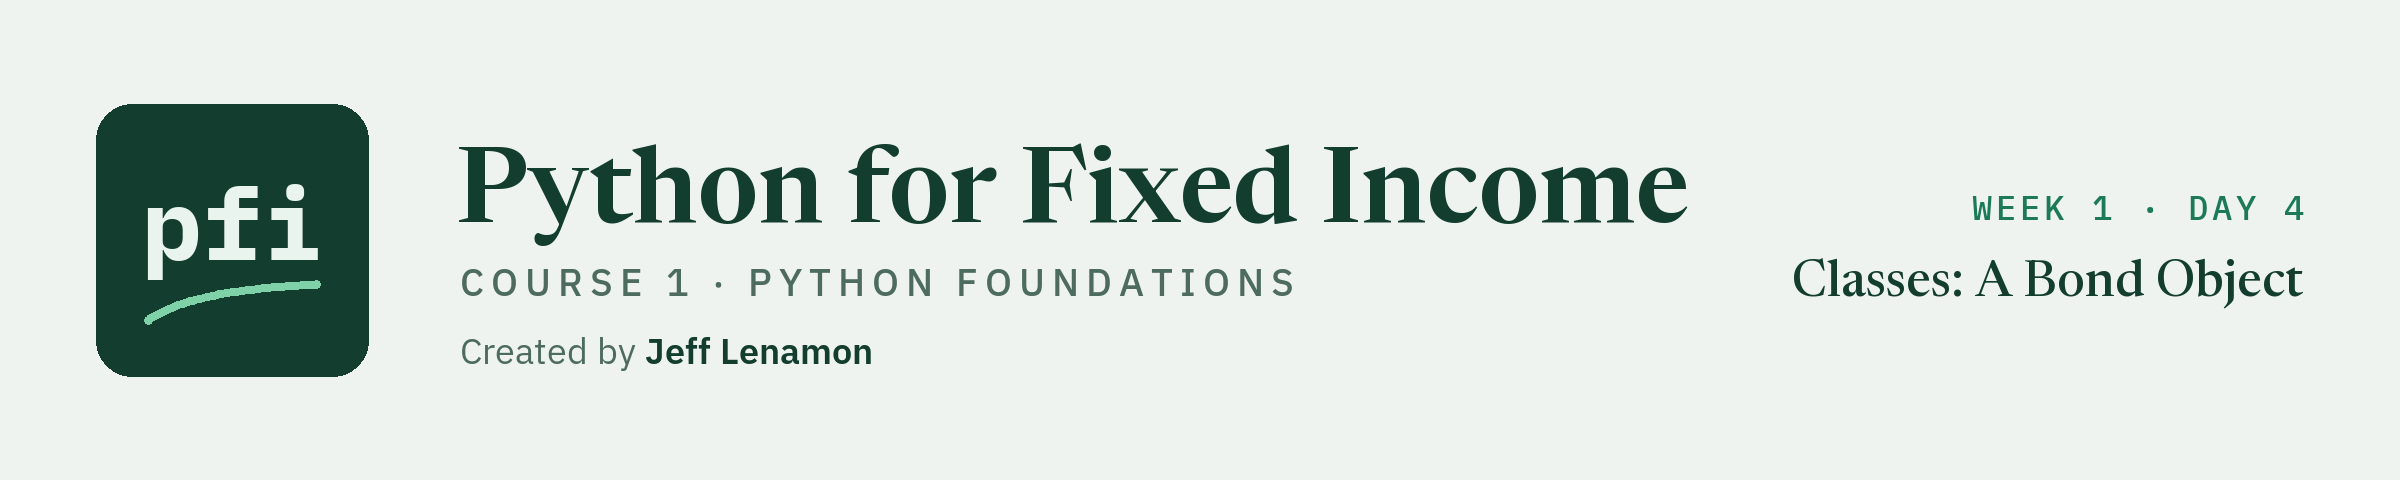

# Classes: A Bond Object

Week 1, Day 4. Bundling a bond's data and its calculations into one object.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course01_python_foundations/week1/day4/04_classes_a_bond_object.ipynb)

## The Desk Lead's Sixth Note

> Every day we hand `current_yield` a coupon and a price, and on Day 3 a price of zero walked straight in. Build me a Bond that carries its own terms, works out its own numbers, refuses a bad price, and prints in words. Then tie the book's value and income from four Bonds.

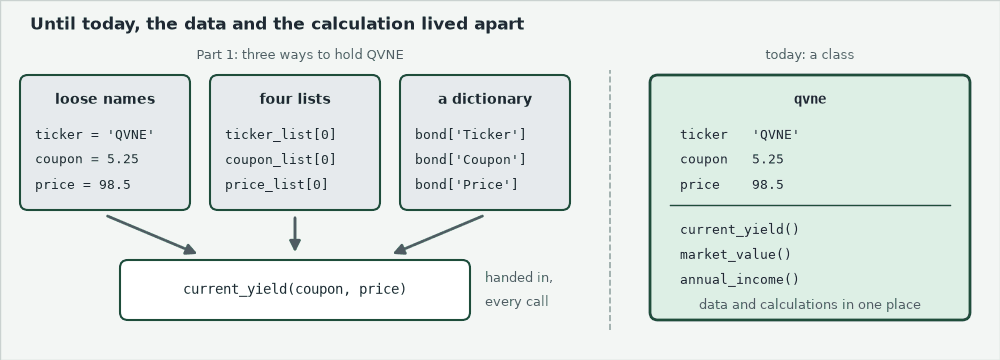

A **class** defines our own kind of object, one that holds data and calculations together.
Code written this way is **object oriented programming**.

**Today the four bonds become four Bond objects.**

## 4.1 Objects Are Already Everywhere

### Every Value Has a Class

Q. What type are QVNE's coupon and ticker, and what does `lower()` do to the ticker?

In [1]:
# QVNE's coupon and ticker, and the type of each
coupon = 5.25
ticker = 'QVNE'
print(type(coupon))
print(type(ticker))
# lower(), the string method from Part 1
print(ticker.lower())

<class 'float'>
<class 'str'>
qvne


Every type is a **class**: Part 1 read `<class 'str'>` as "type str".
5.25 is one object of `float`, 98.5 another: same class, different values.
Every string can run `lower()` because the class `str` defines it.
A class sets out two things: the data each object carries, and the methods it can run.

**Python's own classes cover numbers and text. Now write one for a bond.**

## 4.2 A First Class

### A Blank Form

Q. Define a class named `Bond` that stores a ticker, a coupon, and a price, and works out its own current yield.

In [2]:
# class, a name starting with a capital letter, a colon; the indented body follows
class Bond:
    """A bond: its terms, and its current yield."""
    # a function inside a class is a method
    # its first parameter, self, is the object the method is called on
    def set_terms(self, ticker, coupon, price):
        # store each value on the object
        self.ticker = ticker
        self.coupon = coupon
        self.price = price

    # a method: coupon over price, in percent, from the object's own terms
    def current_yield(self):
        return self.coupon / self.price * 100

Nothing printed: as with a `def` (Part 2), the methods are stored, not run.
`class` is the reserved word Part 1 kept out of names.
In `self.ticker = ticker`, the value handed in, on the right, is stored on the object, on the left.
In VBA terms, a class is Insert, Class Module, and `self` is `Me`.

**A class is a blank form until we fill one in.**

### Make One Bond, Then Ask It

Q. Make a Bond for QVNE, fill in its terms, and ask its type.

Q. Print QVNE's coupon and its current yield.

In [3]:
# calling the class makes one object of it
qvne = Bond()
# fill in its terms; we pass no self, Python supplies it
qvne.set_terms('QVNE', 5.25, 98.5)
print(type(qvne))

<class '__main__.Bond'>


In [4]:
# an attribute: a dot, no brackets
print(qvne.coupon)
# a method: a dot and round brackets
print(qvne.current_yield())

5.25
5.32994923857868


`__main__` is Python's name for the program being run, here this notebook (Part 2's `help()` showed it).
`qvne` is an object of `Bond`, as 5.25 is of `float`: our own data type.
Day 3 called both attributes; in everyday use the word means the data:

<table align="left">
<tr><th align="left">You write</th><th align="left">Brackets</th><th align="left">What it is</th></tr>
<tr><td align="left"><code>qvne.coupon</code></td><td align="left">none</td><td align="left">an attribute: data stored on the bond</td></tr>
<tr><td align="left"><code>qvne.current_yield()</code></td><td align="left">yes</td><td align="left">a method: a calculation the bond runs</td></tr>
</table>
<br clear="left">

We never handed `current_yield()` the coupon or the price.

**It found them on the bond itself, through `self`.**

### What `self` Means

Q. Call the method the long way, through the class, and hand it the bond.

Q. What is `self` outside the class?

In [5]:
# the long way: qvne goes in as self
print(Bond.current_yield(qvne))

5.32994923857868


In [6]:
# self outside a method: this cell is meant to fail
print(self.coupon)

NameError: name 'self' is not defined

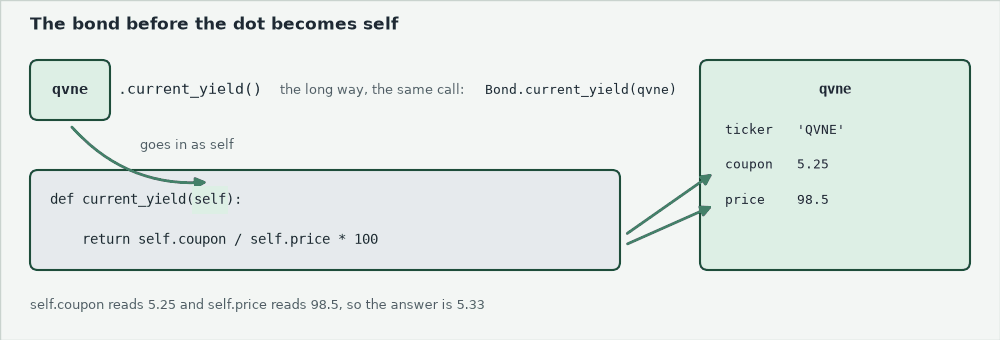

`self` is an ordinary parameter, named so by custom, and like any parameter it exists only inside its method: hence the `NameError`.

**Inside the class `self` is this bond; outside, use the bond's own name.**

### A Second Bond

Q. Make DNMR and print its current yield, then QVNE's again.

In [7]:
# a second object from the same class
dnmr = Bond()
dnmr.set_terms('DNMR', 6.125, 103.25)
print(dnmr.current_yield())
# the first object is unchanged
print(qvne.current_yield())

5.932203389830509
5.32994923857868


Each object carries its own terms.

**One class, many objects. Nothing yet makes them alike.**

## 4.3 The Trouble With Loose Attributes

### A Sector on One Bond Only

Q. Attach a sector to QVNE from outside the class, then ask DNMR for its sector.

In [8]:
# an attribute added from outside the class, to one object
qvne.sector = 'Energy'
print(qvne.sector)

Energy


In [9]:
# this cell is meant to fail
print(dnmr.sector)

AttributeError: 'Bond' object has no attribute 'sector'

Day 3's `AttributeError`: DNMR never got one.
Adding attributes from outside is a bad habit: every object of a class should carry the same attributes.

**Code that works on one bond fails on the next.**

### A Bond Never Filled In

Q. Make PLWK and print its coupon.

In [10]:
# set_terms() is never called: this cell is meant to fail
plwk = Bond()
print(plwk.coupon)

AttributeError: 'Bond' object has no attribute 'coupon'

The object exists, an empty form.

**Every Bond needs the same terms from the moment it is made.**

## 4.4 The Initializer

### Dunder Init

A method named `__init__`, two underscores each side, runs by itself whenever an object is made.
Say "dunder init", for double underscore; it is the **initializer**, where the attributes are set.

Q. Write `Bond` again: five terms set when it is made, and methods for current yield, annual income, and market value.

In [11]:
# Bond again: made and filled in one step, by __init__
class Bond:
    """A bond position: its terms, and the numbers worked out from them."""
    # new: __init__ runs when a Bond is made, and stores its five terms
    def __init__(self, ticker, coupon, maturity, price, face):
        self.ticker = ticker
        self.coupon = coupon
        self.maturity = maturity
        self.price = price
        self.face = face

    def current_yield(self):
        return self.coupon / self.price * 100

    # new: a year's coupon in dollars; the coupon is in percent
    def annual_income(self):
        return self.face * self.coupon / 100

    # new: face at today's price; the price is per 100 face
    def market_value(self):
        return self.face * self.price / 100

### Four Bonds, One Line Each

Q. Make all four bonds, then ask PLWK for its coupon.

In [12]:
# the values in the brackets go to __init__, in order
qvne = Bond('QVNE', 5.25, 2033, 98.5, 1500000)
dnmr = Bond('DNMR', 6.125, 2034, 103.25, 500000)
plwk = Bond('PLWK', 4.75, 2031, 95.0, 750000)
hlvf = Bond('HLVF', 7.5, 2032, 101.0, 250000)
print(plwk.coupon)

4.75


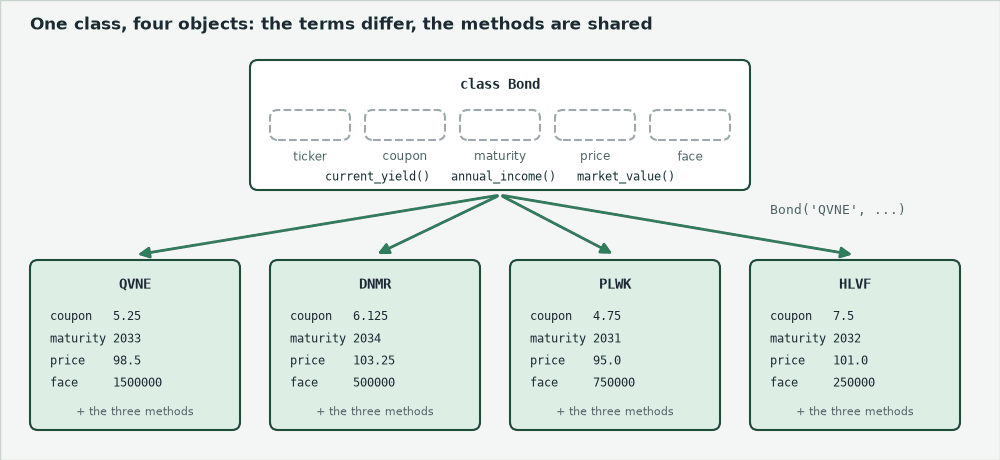

PLWK, the empty form of 4.3, has its terms from the start.

**Making a Bond and filling it in are now one step.**

### Leave a Term Out

Q. Make a fifth bond, OSMC, and leave out its face.

In [13]:
# the face held is missing: this cell is meant to fail
osmc = Bond('OSMC', 5.0, 2035, 100.0)

TypeError: Bond.__init__() missing 1 required positional argument: 'face'

A `TypeError` that names the missing term, `face`, as in Part 2.

**Excel side by side.** Type `=ROUND(98.5)` and Excel says you have entered too few arguments, and will not take the formula.

**The initializer will not make a half-filled Bond.**

## 4.5 Working With an Object

### Value, Income, and a New Price

Q. What are QVNE's market value and its coupon income for a year?

Q. QVNE is marked at 99.25. Set the new price and ask for the value again.

In [14]:
# each method works from QVNE's own terms
print(f'Market value: ${qvne.market_value():,.2f}')
print(f'Annual coupon income: ${qvne.annual_income():,.2f}')

Market value: $1,477,500.00
Annual coupon income: $78,750.00


In [15]:
# an attribute can be changed from outside
qvne.price = 99.25
print(f'Market value: ${qvne.market_value():,.2f}')

Market value: $1,488,750.00


78,750 dollars is Part 2's `annual_income` answer, now asked of the bond.

**`market_value()` works the value out from the price on every call, so it is never out of date.**

### A Stored Value Goes Stale

Q. What if a class works the value out once, when the bond is made, and stores it?

In [16]:
# a second class, for comparison: the value worked out once, when the bond is made
class BondWithStoredValue:
    """A bond that works out its market value once, when it is made."""
    def __init__(self, ticker, price, face):
        self.ticker = ticker
        self.price = price
        self.face = face
        # the market value, worked out here once and stored as an attribute
        self.stored_value = self.face * self.price / 100

In [17]:
# made at 98.5, then marked to 99.25
stale = BondWithStoredValue('QVNE', 98.5, 1500000)
print(f'Before the mark: ${stale.stored_value:,.2f}')
stale.price = 99.25
print(f'After the mark:  ${stale.stored_value:,.2f}')

Before the mark: $1,477,500.00
After the mark:  $1,477,500.00


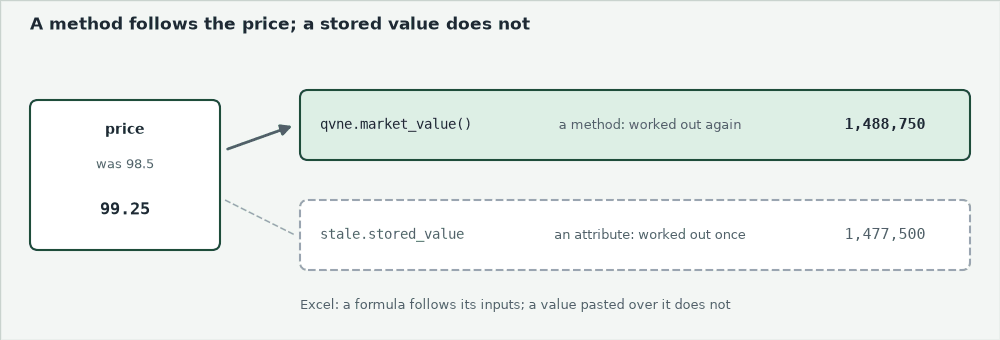

Book cost is different: the price paid at the trade is a fact, and a re-mark does not move it.

**Excel side by side.** A value pasted over a formula looks the same, and stops following the price.

**Store the facts as attributes; calculate anything that depends on them in a method.**

## 4.6 A Bond That Refuses a Bad Price

### A Price of Zero Walks In

Q. The feed sends QVNE a price of 0. Set it, then ask for the current yield.

In [18]:
# plain assignment takes any number: this cell is meant to fail
qvne.price = 0
print(qvne.current_yield())

ZeroDivisionError: float division by zero

The error points at the arithmetic, not at the bad price: Day 3's `ZeroDivisionError`.

**Plain assignment takes any number. A method can check it first.**

### A `mark()` That Refuses

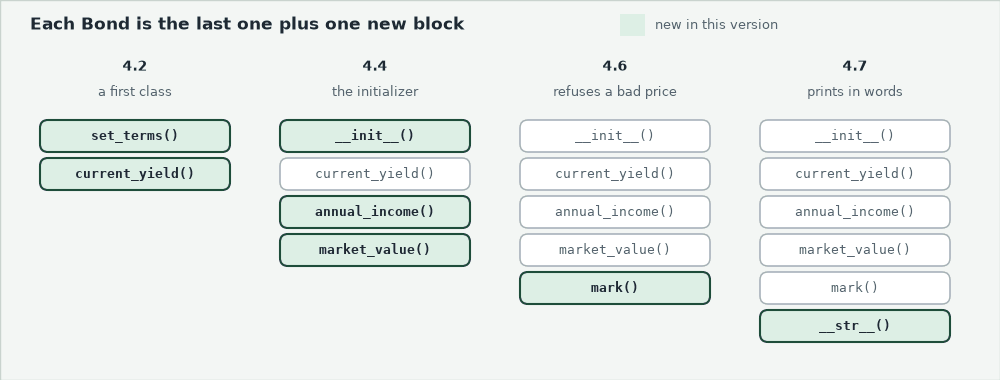

Q. Add a `mark()` method that sets a new price and refuses one of zero or less, with Day 3's `raise`.

In [19]:
# Bond again: 4.4's class, copied, with mark() added at the bottom
class Bond:
    """A bond position: its terms, and the numbers worked out from them."""
    def __init__(self, ticker, coupon, maturity, price, face):
        self.ticker = ticker
        self.coupon = coupon
        self.maturity = maturity
        self.price = price
        self.face = face

    def current_yield(self):
        return self.coupon / self.price * 100

    def annual_income(self):
        return self.face * self.coupon / 100

    def market_value(self):
        return self.face * self.price / 100

    # new: set a new price, refusing one that cannot be right
    def mark(self, new_price):
        if new_price <= 0:
            raise ValueError(f'the price must be above zero, and it is {new_price}')
        self.price = new_price

Only `mark()` checks: `__init__` and a plain `qvne.price = 0` still take any number, so on this desk every new price goes through `mark()`.

### Make Them Again, Then Mark

Q. Does the `qvne` we already have know `mark()`?

Q. Make the four again, then mark QVNE to 99.25, and to 0.

Q. What price does QVNE hold after the refusal?

In [20]:
# qvne was made from the old class: this cell is meant to fail
qvne.mark(99.25)

AttributeError: 'Bond' object has no attribute 'mark'

In [21]:
# qvne was made before mark() existed: make the four again, from the new class
qvne = Bond('QVNE', 5.25, 2033, 98.5, 1500000)
dnmr = Bond('DNMR', 6.125, 2034, 103.25, 500000)
plwk = Bond('PLWK', 4.75, 2031, 95.0, 750000)
hlvf = Bond('HLVF', 7.5, 2032, 101.0, 250000)

In [22]:
# a good mark, then a price of zero: this cell is meant to fail
print(f'Current yield at 98.5:  {qvne.current_yield():.2f} percent')
qvne.mark(99.25)
print(f'Current yield at 99.25: {qvne.current_yield():.2f} percent')
qvne.mark(0)

Current yield at 98.5:  5.33 percent
Current yield at 99.25: 5.29 percent


ValueError: the price must be above zero, and it is 0

In [23]:
# the refused price never reached the bond
print(qvne.price)

99.25


Redefining a class does not change the objects already made.
Two arrows, as on Day 3.

**The Bond refuses a bad price itself: Day 3's `raise`, now inside the class.**

## 4.7 Printing an Object

### What `print` Shows

Q. Print QVNE.

In [24]:
# print a Bond object as it is
print(qvne)

`__main__`, the class name, and where the object sits in memory: a new address on each run, so yours will differ.

**Accurate, and no use to a person.**

### `__str__` Gives It Words

A method named `__str__` returns the text `print` shows for an object; it must return a string.

Q. Add a `__str__` that shows the ticker, coupon, maturity, and current yield, then make the four again and print QVNE.

In [25]:
# Bond again: as in 4.6, with __str__ added at the bottom
class Bond:
    """A bond position: its terms, and the numbers worked out from them."""
    def __init__(self, ticker, coupon, maturity, price, face):
        self.ticker = ticker
        self.coupon = coupon
        self.maturity = maturity
        self.price = price
        self.face = face

    def current_yield(self):
        return self.coupon / self.price * 100

    def annual_income(self):
        return self.face * self.coupon / 100

    def market_value(self):
        return self.face * self.price / 100

    def mark(self, new_price):
        if new_price <= 0:
            raise ValueError(f'the price must be above zero, and it is {new_price}')
        self.price = new_price

    # new: the words print shows; one method can call another through self
    def __str__(self):
        terms = f'{self.ticker} {self.coupon}% of {self.maturity}'
        return f'{terms}, current yield {self.current_yield():.2f}%'

In [26]:
# the four again, from the class with __str__
qvne = Bond('QVNE', 5.25, 2033, 98.5, 1500000)
dnmr = Bond('DNMR', 6.125, 2034, 103.25, 500000)
plwk = Bond('PLWK', 4.75, 2031, 95.0, 750000)
hlvf = Bond('HLVF', 7.5, 2032, 101.0, 250000)
print(qvne)

QVNE 5.25% of 2033, current yield 5.33%


### A List Still Shows the Address

Q. Print QVNE and DNMR in a list.

In [27]:
# a list of two Bonds
print([qvne, dnmr])

[<__main__.Bond object at 0x0000023387F2AE40>, <__main__.Bond object at 0x0000023387F98CD0>]


Methods with two underscores each side are ones Python calls itself:

<table align="left">
<tr><th align="left">Method</th><th align="left">Python calls it when</th></tr>
<tr><td align="left"><code>__init__</code></td><td align="left">a Bond is made</td></tr>
<tr><td align="left"><code>__str__</code></td><td align="left">a Bond is printed</td></tr>
<tr><td align="left"><code>__repr__</code></td><td align="left">a list of Bonds is printed; not written today</td></tr>
</table>
<br clear="left">

**Excel side by side.** `__str__` builds a label from the facts, as a formula does: with ticker, coupon, and maturity in A2:C2, `=A2&" "&B2&"% of "&C2` returns QVNE 5.25% of 2033.

**Now a Bond prints in words.**

## 4.8 A Portfolio of Objects

### Four Bonds in a List

Q. Put the four bonds in a list, and print each one.

In [28]:
# a list of Bond objects: the book
portfolio = [qvne, dnmr, plwk, hlvf]
# print() calls each bond's __str__
for bond in portfolio:
    print(bond)

QVNE 5.25% of 2033, current yield 5.33%
DNMR 6.125% of 2034, current yield 5.93%
PLWK 4.75% of 2031, current yield 5.00%
HLVF 7.5% of 2032, current yield 7.43%


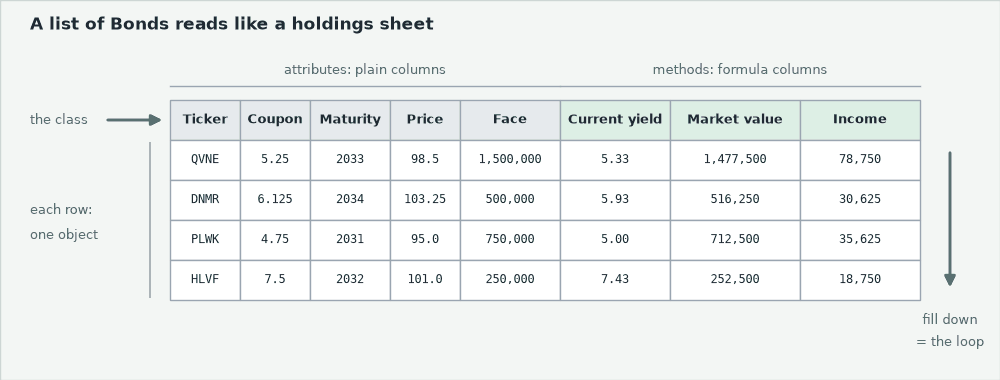

Part 2's loops stepped through four lists at once with `zip()`; here one list is enough.

**Excel side by side.** In an Excel Table (Insert, Table), a new row picks up the formula columns by itself, as a new `Bond` comes with its methods.

**Each bond carries everything it needs.**

### Discount Bonds and Their Yield

Q. Which bonds trade below 100?

Q. Put each bond's coupon and current yield in a table.

Q. Draw the two side by side.

In [29]:
# Part 2's comprehension with an if, asking each bond for its price
discount_tickers = [bond.ticker for bond in portfolio if bond.price < 100]
print(discount_tickers)

['QVNE', 'PLWK']


In [30]:
# pandas, imported as in Day 0
import pandas as pd
# a dictionary of lists becomes a table; every number comes from a bond
table = pd.DataFrame({'Ticker': [bond.ticker for bond in portfolio],
                      'Coupon': [bond.coupon for bond in portfolio],
                      'Current yield': [bond.current_yield() for bond in portfolio]})
table

,Ticker,Coupon,Current yield
0,QVNE,5.250,5.329949
1,DNMR,6.125,5.932203
2,PLWK,4.750,5.000000
3,HLVF,7.500,7.425743


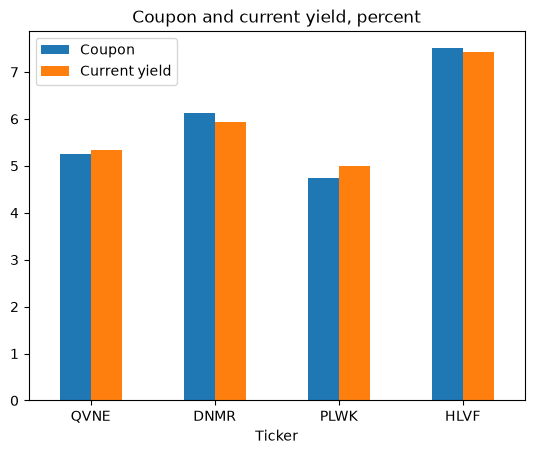

In [31]:
# with no y=, plot.bar draws every number column
chart = table.plot.bar(x='Ticker', rot=0, title='Coupon and current yield, percent')

**Excel side by side.** With tickers in A2:A5 and prices in D2:D5, `=FILTER(A2:A5,D2:D5<100)` returns the same two; `FILTER` needs Excel 2021 or later, or Microsoft 365.

**Below par, the current yield is above the coupon; above par, below it.**

### Rank by Value, Pick the Top Coupon

Q. Rank the bonds by market value, largest first.

Q. Which bond has the highest coupon?

In [32]:
# sorted() with a lambda key, as in Part 2: each bond's own market_value()
ranked = sorted(portfolio, key=lambda bond: bond.market_value(), reverse=True)
for bond in ranked:
    print(f'{bond.ticker}: ${bond.market_value():,.2f}')

QVNE: $1,477,500.00
PLWK: $712,500.00
DNMR: $516,250.00
HLVF: $252,500.00


In [33]:
# max() takes a key= too, and hands back the whole bond
highest = max(portfolio, key=lambda bond: bond.coupon)
print(highest)

HLVF 7.5% of 2032, current yield 7.43%


**Excel side by side.** With tickers in A2:A5 and coupons in B2:B5, `=INDEX(A2:A5,MATCH(MAX(B2:B5),B2:B5,0))` returns the top coupon's ticker: `MAX` finds the number, `MATCH` its row, `INDEX` the ticker on that row.

### The Book From Four Bonds

Q. Total the book's market value and annual income from the four Bonds.

Q. Tie them to the desk's 2,958,750 and 163,750 dollars.

In [34]:
# each total asks every bond for its own number
book_value = sum([bond.market_value() for bond in portfolio])
book_income = sum([bond.annual_income() for bond in portfolio])

In [35]:
# Day 3's rule: a total that matters is tied with assert
import math
assert math.isclose(book_value, 2958750), 'value does not tie'
assert math.isclose(book_income, 163750), 'income does not tie'
print(f'Book ties: ${book_value:,.2f} value, ${book_income:,.2f} income')

Book ties: $2,958,750.00 value, $163,750.00 income


Part 2 and Day 3 reached the same totals from four lists; at these prices market value equals cost.

**Four Bonds carry the book, and its totals tie.**

## You Can Now

By the end of this notebook, you can:

* Read a class: its attributes, its methods, and `self`.
* Make a `Bond` in one line with an initializer.
* Store the facts as attributes and calculate the rest in methods.
* Make a method refuse a bad value with `raise`.
* Make an object print in words a person can read.
* Loop over a list of objects.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

A second desk holds three positions.

<table align="left">
<tr><th align="left">Ticker</th><th align="left">Face held</th><th align="left">Price</th></tr>
<tr><td align="left">TRNW</td><td align="left">2,000,000</td><td align="left">96.25</td></tr>
<tr><td align="left">OSMC</td><td align="left">1,250,000</td><td align="left">100.00</td></tr>
<tr><td align="left">CLDB</td><td align="left">500,000</td><td align="left">104.50</td></tr>
</table>
<br clear="left">

Replace each `...` with your own code, then run the check cell under it.
Run the next cell first: it defines `check`, which marks your answers.

In [36]:
def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ... or answer is None:
        print(label + ': not attempted yet')
    elif answer == expected:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)

### Exercise 1

Q. Complete the class **Position** below. The initializer should store the ticker, face, and price. The method `market_value()` should return face times price divided by 100. Then the code creates the TRNW position and stores its market value in **ex1_market_value**.

In [37]:
class Position:
    def __init__(self, ticker, face, price):
        ...

    def market_value(self):
        return ...


trnw = Position('TRNW', 2000000, 96.25)
ex1_market_value = trnw.market_value()

In [38]:
check('Exercise 1', ex1_market_value, 1925000.0)

Exercise 1: not attempted yet


### Exercise 2

Q. Write the class again and add a method `is_premium()` that returns True when the price is above 100 and False otherwise. Then create all three positions. The code stores whether CLDB is at a premium in **ex2_cldb_premium** and whether OSMC is in **ex2_osmc_premium**.

In [39]:
class Position:
    def __init__(self, ticker, face, price):
        ...

    def market_value(self):
        return ...

    def is_premium(self):
        return ...


trnw = Position('TRNW', 2000000, 96.25)
osmc = Position('OSMC', 1250000, 100.0)
cldb = Position('CLDB', 500000, 104.5)

ex2_cldb_premium = cldb.is_premium()
ex2_osmc_premium = osmc.is_premium()

In [40]:
check('Exercise 2 CLDB', ex2_cldb_premium, True)
check('Exercise 2 OSMC', ex2_osmc_premium, False)

Exercise 2 CLDB: not attempted yet
Exercise 2 OSMC: not attempted yet


### Exercise 3

Q. Put the three positions in a list and use a loop to find the total market value. Store it in **ex3_total_value**.

In [41]:
ex3_total_value = ...

In [42]:
check('Exercise 3', ex3_total_value, 3697500.0)

Exercise 3: not attempted yet


### Exercise 4

Q. The desk sells 500,000 face of TRNW, leaving 1,500,000. Update the face on the TRNW object, then store its new market value in **ex4_market_value**.

In [43]:
ex4_market_value = ...

In [44]:
check('Exercise 4', ex4_market_value, 1443750.0)

Exercise 4: not attempted yet


### Exercise 5

Q. Write the class once more and add a `__str__` method, so that printing a position shows its ticker, its face with thousands separators, and its price to 2 decimals, in this form: `CLDB 500,000 at 104.50`. Build the text with an f-string. Then store `str(cldb)` in **ex5_text**. `str()` gives the same text that `print()` shows.

In [45]:
class Position:
    def __init__(self, ticker, face, price):
        ...

    def market_value(self):
        return ...

    # add the __str__ method here


cldb = Position('CLDB', 500000, 104.5)
ex5_text = ...

In [46]:
check('Exercise 5', ex5_text, 'CLDB 500,000 at 104.50')

Exercise 5: not attempted yet


### Exercise 6: AI check

An AI assistant wrote a position class whose `mark()` sets a new price; it has one bug.
The code makes 2,000,000 face at 96.25, marks it to 97.00, and prints the market value.

Q. Before you run it, work out what the market value should be after the mark. Then run the code. Does it agree with you?

Q. Find the bug and fix the code below, so that **ex6_value_after_mark** holds the right answer.

In [47]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
class MarkedPosition:
    def __init__(self, ticker, face, price):
        self.ticker = ticker
        self.face = face
        self.price = price

    def market_value(self):
        return self.face * self.price / 100

    def mark(self, new_price):
        price = new_price


marked = MarkedPosition('TRNW', 2000000, 96.25)
marked.mark(97.0)
ex6_value_after_mark = marked.market_value()
print(f'Market value after the mark: {ex6_value_after_mark:,.2f}')

Market value after the mark: 1,925,000.00


In [48]:
check('Exercise 6', ex6_value_after_mark, 1940000.0)

Exercise 6: not yet. You have 1925000.0


## Congratulations!

The note is answered:

<table align="left">
<tr><th align="left">The note asked</th><th align="left">Answer</th></tr>
<tr><td align="left">Its own terms and numbers</td><td align="left"><code>current_yield()</code>, <code>market_value()</code>, <code>annual_income()</code>, nothing handed in</td></tr>
<tr><td align="left">Refuse a bad price</td><td align="left"><code>qvne.mark(0)</code> stops with a <code>ValueError</code> that says why</td></tr>
<tr><td align="left">Print in words</td><td align="left"><code>QVNE 5.25% of 2033, current yield 5.33%</code></td></tr>
<tr><td align="left">The book from four Bonds</td><td align="left">two <code>assert</code> lines tie the value and the income</td></tr>
</table>
<br clear="left">

You wrote your own data type.
On an object, a dot now reads plainly: no brackets, data; brackets, a calculation.
Be proud: you can read every line of a class and say what it does.
On Day 5 a desk takes over six bonds typed into an email, and the case study puts the whole week to work, from loose values to one pandas table.